# Task 2 — SQL & Data Extraction
### Day 15-17: Python + SQL Integration

This notebook demonstrates:
- Connecting Python to the database via `sqlalchemy` (SQLite backend, PostgreSQL-ready)
- Executing SQL directly from the notebook
- Loading query results into DataFrames with `pandas.read_sql()`
- Parameterized queries to avoid SQL injection
- Reusing the `db_utils.py` module for all connections


In [1]:
import sys
sys.path.append('..')  # so db_utils.py is importable from /project

import pandas as pd
import matplotlib.pyplot as plt

from db_utils import get_engine, run_query, run_parametrized, execute_statement

pd.set_option('display.max_rows', 15)
%matplotlib inline


## 1. Connect to the database
Using the reusable `db_utils.get_engine()` — defaults to the local SQLite `shop.db`, but can point at PostgreSQL by setting `DB_BACKEND=postgres` and `DB_URL`.

In [2]:
engine = get_engine()  # SQLite by default
run_query(engine, "SELECT name FROM sqlite_master WHERE type='table'")


,name
0,customers
1,categories
2,products
3,orders
4,order_items


## 2. Basic SQL fundamentals recap
SELECT / WHERE / ORDER BY / LIMIT, straight into a DataFrame.

In [3]:
df = run_query(engine, '''
    SELECT order_id, customer_id, order_date, order_total
    FROM orders
    WHERE status = 'completed'
    ORDER BY order_total DESC
    LIMIT 10
''')
df


,order_id,customer_id,order_date,order_total
0,2375,395,2026-05-18,44865.41
1,175,206,2025-11-16,40773.58
2,1287,256,2026-04-23,37905.65
3,3410,165,2026-04-09,34911.50
4,896,203,2026-04-24,34852.03
5,168,172,2026-05-03,34589.46
6,1485,289,2026-06-08,34455.56
7,787,152,2026-05-06,33560.12
8,431,59,2026-04-02,33399.44
9,816,309,2025-11-28,33369.06


### JOINs (INNER / LEFT / RIGHT / FULL) — verified working in `sql/queries.sql`
Here's the INNER JOIN pulled through pandas:

In [4]:
df_joined = run_query(engine, '''
    SELECT o.order_id, c.full_name, p.product_name, oi.quantity, oi.unit_price
    FROM orders o
    JOIN customers c    ON c.customer_id = o.customer_id
    JOIN order_items oi ON oi.order_id = o.order_id
    JOIN products p     ON p.product_id = oi.product_id
    LIMIT 10
''')
df_joined


,order_id,full_name,product_name,quantity,unit_price
0,1,Pooja Reddy,Cookbook,2,2278.80
1,1,Pooja Reddy,Football,2,3414.08
2,2,Rohan Chopra,Cricket Bat,1,2078.69
3,2,Rohan Chopra,Blender,1,4894.16
4,3,Kabir Khan,Football,1,3414.08
5,3,Kabir Khan,Smartwatch,1,4472.69
6,4,Ananya Das,Football,3,3414.08
7,4,Ananya Das,Face Serum,2,2416.39
8,5,Pooja Singh,Blender,1,4894.16
9,6,Diya Das,Sunscreen SPF50,1,4680.62


## 3. Parameterized queries (SQL-injection safe)
User-supplied values are bound with `:name` placeholders — never string-concatenated into the query.

In [5]:
city = 'Delhi'
min_spend = 50000

df_city = run_parametrized(engine, '''
    SELECT c.full_name, c.city, SUM(o.order_total) AS total_spend
    FROM customers c
    JOIN orders o ON o.customer_id = c.customer_id
    WHERE c.city = :city
      AND o.status = 'completed'
    GROUP BY c.full_name, c.city
    HAVING SUM(o.order_total) > :min_spend
    ORDER BY total_spend DESC
''', {"city": city, "min_spend": min_spend})

df_city


,full_name,city,total_spend
0,Zoya Bose,Delhi,150416.45
1,Diya Joshi,Delhi,142888.00
2,Arjun Singh,Delhi,136399.28
3,Rohan Mehta,Delhi,128668.73
4,Zoya Mehta,Delhi,120313.05
...,...,...,...
20,Vivaan Khan,Delhi,61188.51
21,Meera Verma,Delhi,54164.34
22,Sanjay Iyer,Delhi,54138.34
23,Arjun Gupta,Delhi,53956.26


## 4. Business queries
### 4.1 Monthly sales trend

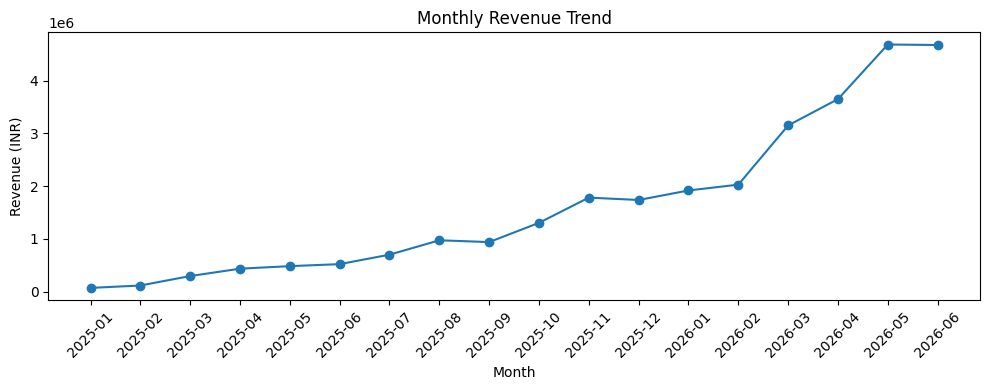

In [6]:
df_monthly = run_query(engine, '''
    SELECT strftime('%Y-%m', order_date) AS month,
           COUNT(*) AS orders_count,
           ROUND(SUM(order_total), 2) AS monthly_revenue
    FROM orders
    WHERE status = 'completed'
    GROUP BY month
    ORDER BY month
''')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df_monthly['month'], df_monthly['monthly_revenue'], marker='o')
ax.set_title('Monthly Revenue Trend')
ax.set_xlabel('Month')
ax.set_ylabel('Revenue (INR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 4.2 Top 10 customers by revenue

In [7]:
df_top10 = run_query(engine, '''
    SELECT c.customer_id, c.full_name, c.city,
           ROUND(SUM(o.order_total), 2) AS total_revenue,
           COUNT(o.order_id) AS orders_placed
    FROM customers c
    JOIN orders o ON o.customer_id = c.customer_id
    WHERE o.status = 'completed'
    GROUP BY c.customer_id, c.full_name, c.city
    ORDER BY total_revenue DESC
    LIMIT 10
''')
df_top10


,customer_id,full_name,city,total_revenue,orders_placed
0,338,Rohan Kapoor,Mumbai,193363.75,17
1,393,Zoya Kapoor,Jaipur,176672.38,16
2,9,Neha Gupta,Pune,166408.97,14
3,48,Pooja Singh,Chennai,161723.68,13
4,388,Nikhil Bose,Noida,158148.29,13
5,58,Ritu Iyer,Mumbai,157727.32,12
6,330,Aditya Sharma,Chennai,154963.61,16
7,119,Ritu Sharma,Pune,154939.60,12
8,199,Neha Khan,Hyderabad,154023.92,15
9,277,Vivaan Reddy,Chennai,151984.37,11


### 4.3 Customer retention rate (month-over-month)

In [8]:
df_retention = run_query(engine, '''
    WITH monthly_customers AS (
        SELECT DISTINCT customer_id, strftime('%Y-%m', order_date) AS month
        FROM orders WHERE status = 'completed'
    ),
    retention AS (
        SELECT cur.month,
               COUNT(DISTINCT cur.customer_id) AS active_customers,
               COUNT(DISTINCT prev.customer_id) AS retained_customers
        FROM monthly_customers cur
        LEFT JOIN monthly_customers prev
               ON prev.customer_id = cur.customer_id
              AND prev.month = strftime('%Y-%m', date(cur.month || '-01', '-1 month'))
        GROUP BY cur.month
    )
    SELECT month, active_customers, retained_customers,
           ROUND(100.0 * retained_customers / active_customers, 1) AS retention_rate_pct
    FROM retention
    ORDER BY month
''')
df_retention


,month,active_customers,retained_customers,retention_rate_pct
0,2025-01,4,0,0.0
1,2025-02,15,1,6.7
2,2025-03,23,3,13.0
3,2025-04,35,11,31.4
4,2025-05,45,16,35.6
...,...,...,...,...
13,2026-02,156,73,46.8
14,2026-03,215,93,43.3
15,2026-04,229,130,56.8
16,2026-05,247,152,61.5


### 4.4 Product category performance

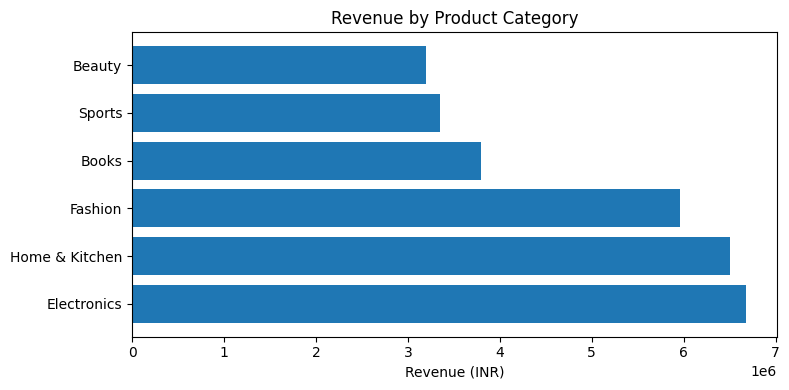

,category_name,units_sold,revenue,pct_of_total_revenue
0,Electronics,1909,6682596.83,22.7
1,Home & Kitchen,1548,6507222.80,22.1
2,Fashion,1652,5958929.23,20.2
3,Books,1030,3800108.48,12.9
4,Sports,1157,3347462.14,11.3
5,Beauty,1082,3197746.07,10.8


In [9]:
df_cat = run_query(engine, '''
    WITH category_sales AS (
        SELECT cat.category_name,
               SUM(oi.quantity) AS units_sold,
               SUM(oi.quantity * oi.unit_price) AS revenue
        FROM categories cat
        JOIN products p     ON p.category_id = cat.category_id
        JOIN order_items oi ON oi.product_id = p.product_id
        JOIN orders o       ON o.order_id = oi.order_id
        WHERE o.status = 'completed'
        GROUP BY cat.category_name
    )
    SELECT category_name, units_sold, ROUND(revenue, 2) AS revenue,
           ROUND(100.0 * revenue / SUM(revenue) OVER (), 1) AS pct_of_total_revenue
    FROM category_sales
    ORDER BY revenue DESC
''')

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(df_cat['category_name'], df_cat['revenue'])
ax.set_xlabel('Revenue (INR)')
ax.set_title('Revenue by Product Category')
plt.tight_layout()
plt.show()

df_cat


### 4.5 7-day moving average and cumulative revenue

In [10]:
df_ma = run_query(engine, '''
    WITH daily_revenue AS (
        SELECT order_date, SUM(order_total) AS revenue
        FROM orders WHERE status = 'completed'
        GROUP BY order_date
    )
    SELECT order_date, revenue,
           ROUND(AVG(revenue) OVER (ORDER BY order_date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW), 2) AS moving_avg_7day,
           ROUND(SUM(revenue) OVER (ORDER BY order_date ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW), 2) AS cumulative_revenue
    FROM daily_revenue
    ORDER BY order_date
''')
df_ma.head(15)


,order_date,revenue,moving_avg_7day,cumulative_revenue
0,2025-01-06,12265.24,12265.24,12265.24
1,2025-01-09,13202.20,12733.72,25467.44
2,2025-01-13,20885.52,15450.99,46352.96
3,2025-01-14,13352.27,14926.31,59705.23
4,2025-01-27,13418.07,14624.66,73123.30
5,2025-02-01,19397.96,15420.21,92521.26
6,2025-02-04,12231.87,14964.73,104753.13
7,2025-02-05,5896.96,14054.98,110650.09
8,2025-02-09,5732.25,12987.84,116382.34
9,2025-02-12,13064.48,11870.55,129446.82


## 5. Views for frequently used queries
Created once in `sql/queries.sql` (`vw_customer_ltv`, `vw_monthly_category_revenue`) — queried here like ordinary tables.

In [11]:
run_query(engine, "SELECT * FROM vw_customer_ltv ORDER BY lifetime_value DESC LIMIT 10")


,customer_id,full_name,city,total_orders,lifetime_value,first_order_date,last_order_date
0,338,Rohan Kapoor,Mumbai,17,193363.75,2026-04-06,2026-06-28
1,393,Zoya Kapoor,Jaipur,16,176672.38,2026-04-07,2026-06-26
2,9,Neha Gupta,Pune,14,166408.97,2025-08-12,2026-06-07
3,48,Pooja Singh,Chennai,13,161723.68,2025-09-02,2026-06-21
4,388,Nikhil Bose,Noida,13,158148.29,2025-07-27,2026-05-03
5,58,Ritu Iyer,Mumbai,12,157727.32,2025-05-19,2026-06-17
6,330,Aditya Sharma,Chennai,16,154963.61,2025-07-06,2026-06-06
7,119,Ritu Sharma,Pune,12,154939.60,2025-08-05,2026-04-13
8,199,Neha Khan,Hyderabad,15,154023.92,2025-09-30,2026-06-25
9,277,Vivaan Reddy,Chennai,11,151984.37,2025-04-26,2026-05-05


## 6. Query optimization: EXPLAIN QUERY PLAN + indexing
Indexes were added on the main filter/join columns in `sql/queries.sql`. Confirming the planner now uses them:

In [12]:
run_query(engine, '''
    EXPLAIN QUERY PLAN
    SELECT customer_id, COUNT(*) FROM orders WHERE customer_id = 42 GROUP BY customer_id
''')


,id,parent,notused,detail
0,6,0,0,SEARCH orders USING COVERING INDEX idx_orders_...


## 7. Exporting a result for downstream use

In [13]:
df_monthly.to_csv('../data/monthly_sales_trend.csv', index=False)
print('Saved.')


Saved.


---
## Summary

| Deliverable | Status |
|---|---|
| Local SQLite database (`shop.db`) with cleaned, realistic data | ✅ |
| `sql/queries.sql` — SELECT/WHERE/JOIN/GROUP BY/subqueries/CTEs/window functions | ✅ |
| Business queries: monthly trend, top customers, retention, category performance, moving averages | ✅ |
| Views for reusable queries | ✅ |
| `EXPLAIN QUERY PLAN` + indexing | ✅ |
| `db_utils.py` reusable connection module (SQLite + PostgreSQL) | ✅ |
| Python ↔ SQL integration via SQLAlchemy + `pandas.read_sql()` | ✅ |
| Parameterized queries (SQL-injection safe) | ✅ |
